# Семинар: три способа адаптации π₀ с D0 на D1

Сравним **full SFT**, **action-expert SFT** и **residual RL**. Вначале один раз обучена полная D0-модель из официального pi0_base; все методы стартуют из неё. Все 50 native demonstrations каждой задачи остаются в SFT. Новые generated evaluation scenes относятся к знакомым задачам, это не OOD.

Цель практики: проследить путь **weights + normalization → scene → observations → action → rollout → video → SR**, затем оценить сохранение D0 и освоение D1. Мы используем уже завершённые 300 финальных эпизодов. Повторный запуск проверяет и переиспользует их, не увеличивая N.

[Модели и артефакты](https://huggingface.co/qrvmil/pi0-d0-d1-three-adaptations-20261020/tree/main), [код и preregistration](https://github.com/qrvmil/maniskill_myws/tree/exp/pi0-d0-d1-three-adaptations-20261020).

На этой машине используется подготовленный kernel `/workspace/pi0_venv/bin/python`. Для чтения сохранённых outputs GPU не нужна: notebook уже содержит три видео, а все300 доступны на HF.

Для выполнения на другой машине воспроизведите pinned OpenPI environment и LIBERO из [runtime inventory](https://github.com/qrvmil/maniskill_myws/blob/exp/pi0-d0-d1-three-adaptations-20261020/experiments/pi0_d0_d1_three_adaptations/evidence/runtime.json), затем simulator/notebook зависимости из `scripts/adaptation/install_runtime.sh`. Код должен находиться в `/workspace/pi0_experiment`, LIBERO — в `/workspace/LIBERO`. Metadata сохраняет абсолютные пути; используйте такие соответствия HF → local и проверяйте `inventory.json`/SHA256 после скачивания:

| Путь в HF repo | Путь относительно `/workspace/pi0_three` |
|---|---|
| `normalization/d0/` | `assets/normalization/d0/` |
| `selection/final_selection.json` | `final_selection.json` |
| `checkpoints/d0/3000/` | `sft/d0/3000/` |
| `checkpoints/full/1500/` | `sft/full/1500/` |
| `checkpoints/expert/1500/` | `sft/expert/1500/` |
| `checkpoints/residual/final/` | `rl/final/` |
| `reset_states/final/` | `reset_states/final/` |
| `final/` | `final/` |

Таблицы `results/` уже находятся в experiment directory GitHub. Native demonstrations для повторного просмотра этого семинара не требуются: обучение и финальные эпизоды завершены, здесь мы проверяем и переиспользуем их.

In [1]:
import os, sys, json
from pathlib import Path
os.environ['MUJOCO_GL'] = 'egl'
os.environ['JAX_PLATFORMS'] = 'cpu'  # π₀ и residual используют PyTorch CUDA
repo = Path('/workspace/pi0_experiment')
sys.path[:0] = [str(repo/'scripts/adaptation'), str(repo/'src'), '/workspace/LIBERO']
from notebook_tools import SeminarPolicy
from common import WORK, ROOT, HF_REPO
selection = json.loads((WORK/'final_selection.json').read_text())
assert set(selection) == {'full', 'expert', 'residual'}
selection

{'full': {'checkpoint': '/workspace/pi0_three/sft/full/1500',
  'weights_sha256': 'a9a46f6779060ed7b85dcfc671254fe329fff66d7a411c126d1cdda2bdd41c1d',
  'normalization_sha256': 'a06c2e745bf91d8dd6a3fa6377560d3104e6cad621da4ecebe1372c74bbb388e',
  'selection': 'fixed preregistered last budget; no final evaluations used',
  'hf_repo': 'qrvmil/pi0-d0-d1-three-adaptations-20261020'},
 'expert': {'checkpoint': '/workspace/pi0_three/sft/expert/1500',
  'weights_sha256': 'd76e243072b0196b68503afdb8aa32fcfe9dc623d771bc2e2d5d5a880812e40d',
  'normalization_sha256': 'a06c2e745bf91d8dd6a3fa6377560d3104e6cad621da4ecebe1372c74bbb388e',
  'selection': 'fixed preregistered last budget; no final evaluations used',
  'hf_repo': 'qrvmil/pi0-d0-d1-three-adaptations-20261020'},
 'residual': {'checkpoint': '/workspace/pi0_three/rl/final',
  'weights_sha256': 'c4f2b9853e00fc9c3eab31492d48bcebd25f35a3d334b0dde8ffd59310319094',
  'normalization_sha256': 'a06c2e745bf91d8dd6a3fa6377560d3104e6cad621da4ecebe1372c7

## Данные, общий старт и честная оценка

D0: «pick up the black bowl from table center and place it on the plate»; D1: «pick up the black bowl next to the plate and place it on the plate». Native observations записаны после action; обучающая пара — `obs[i] → action[i+1]`. Камеры повёрнуты на 180°, далее официальный resize/pad. D0-only normalization фиксирована, inverse normalization применяется один раз перед OSC clipping.

3000 updates × batch8 на D0; затем два SFT по 1500 updates × batch8 с новыми optimizer states. Full обновляет всю π₀, expert — action expert и state/action/time projections, заморозив PaliGemma. Residual замораживает всю исходную D0 π₀.

Для каждой пары task/seed методы получают одинаковые сохранённые generated reset states и поток flow noise. Horizon220, replan5; финальные seeds30000–30049 не использовались в RL или validation. Наша демонстрация ниже читает seed30000 из этой фиксированной таблицы.

## 1. Full SFT

Загрузим веса и ту же D0 normalization. Создадим D1-сцену с сохранённым reset state и проверим hash. Затем вычислим первое действие и сверим его с финальным эпизодом.

In [2]:
policy = SeminarPolicy('full')
print('Checkpoint:', policy.checkpoint)
print('D0 normalization SHA256:', policy.norm)

/workspace/pi0_venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Checkpoint: /workspace/pi0_three/sft/full/1500
D0 normalization SHA256: a06c2e745bf91d8dd6a3fa6377560d3104e6cad621da4ecebe1372c74bbb388e


In [3]:
observation = policy.scene('D1', seed=30000)
print('Prompt:', observation['prompt'])
print('State:', observation['state'])
print('Images:', observation['images'].shape, observation['images'].dtype)
print('Reset SHA256:', observation['reset_hash'])
print('Initial observation SHA256:', observation['initial_observation_hash'])

[robosuite WARNING] No private macro file found! (macros.py:53)


[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)


[robosuite WARNING] To setup, run: python /workspace/pi0_venv/lib/python3.11/site-packages/robosuite/scripts/setup_macros.py (macros.py:55)


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


Prompt: pick up the black bowl next to the plate and place it on the plate
State: [-2.0846467e-01  2.4891632e-12  1.1732795e+00  3.1403394e+00
  7.7350385e-04 -8.9222006e-02  3.8722824e-02 -3.8722765e-02]
Images: (2, 128, 128, 3) uint8
Reset SHA256: fdca0d2f5f05645af644c339c68139b679a2d8cc2f6b83112d224b3896d6acbe
Initial observation SHA256: b0dd88d8a24a45b3b352663860ed9530a1d70ea025c272f3374ac59a5c19ef21


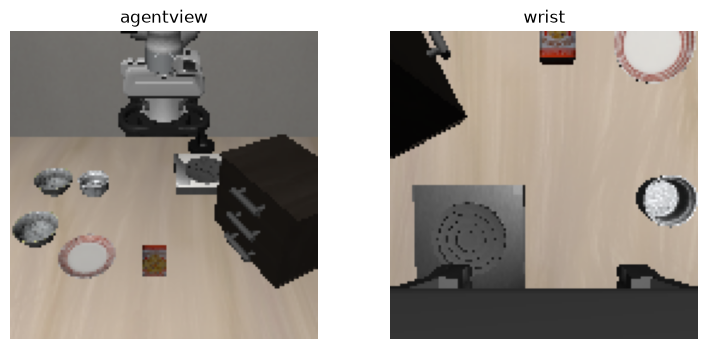

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, image, title in zip(axes, observation['images'], ['agentview', 'wrist']):
    ax.imshow(image); ax.set_title(title); ax.axis('off')
plt.show()

In [5]:
action = policy.action()
action

{'base': array([ 1.2622307e-01,  3.1356114e-01,  1.6301699e-01,  2.0222447e-04,
        -5.0311178e-02, -2.1779913e-02, -1.0000000e+00], dtype=float32),
 'unit_residual': array([0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 'executed_action': array([ 1.2622307e-01,  3.1356114e-01,  1.6301699e-01,  2.0222447e-04,
        -5.0311178e-02, -2.1779913e-02, -1.0000000e+00], dtype=float32),
 'checked_against_recorded_first_action': True}

`executed_action` — семь bounded команд OSC: translation, rotation и gripper. Chunk длиной50 предсказывается заново каждые5 исполненных actions. Rollout ниже переиспользует проверенный финальный episode; видео включает обе камеры и terminal frame.

In [6]:
rollout = policy.rollout()
{k: rollout[k] for k in ['method', 'task', 'seed', 'success', 'length', 'reset_hash', 'trajectory_hash']}

{'method': 'full',
 'task': 'D1',
 'seed': 30000,
 'success': True,
 'length': 112,
 'reset_hash': 'fdca0d2f5f05645af644c339c68139b679a2d8cc2f6b83112d224b3896d6acbe',
 'trajectory_hash': '79061a585aabdb70e8b1d90961c391f233b722a83c950cfe8153cde67c2ad3bd'}

In [7]:
policy.video(rollout)

In [8]:
policy.success_rates()

{'D0': {'n': 50,
  'successes': 0,
  'success_rate': 0.0,
  'wilson_95ci': [6.938893903907228e-18, 0.07134759913335872],
  'mean_episode_length': 220.0},
 'D1': {'n': 50,
  'successes': 20,
  'success_rate': 0.4,
  'wilson_95ci': [0.27608389730256544, 0.5381856225241064],
  'mean_episode_length': 178.18}}

In [9]:
policy.close()
del policy

## 2. Action-expert SFT

Загрузим веса и ту же D0 normalization. Создадим D1-сцену с сохранённым reset state и проверим hash. Затем вычислим первое действие и сверим его с финальным эпизодом.

In [10]:
policy = SeminarPolicy('expert')
print('Checkpoint:', policy.checkpoint)
print('D0 normalization SHA256:', policy.norm)

Checkpoint: /workspace/pi0_three/sft/expert/1500
D0 normalization SHA256: a06c2e745bf91d8dd6a3fa6377560d3104e6cad621da4ecebe1372c74bbb388e


In [11]:
observation = policy.scene('D1', seed=30000)
print('Prompt:', observation['prompt'])
print('State:', observation['state'])
print('Images:', observation['images'].shape, observation['images'].dtype)
print('Reset SHA256:', observation['reset_hash'])
print('Initial observation SHA256:', observation['initial_observation_hash'])

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


Prompt: pick up the black bowl next to the plate and place it on the plate
State: [-2.0846467e-01  2.4891632e-12  1.1732795e+00  3.1403394e+00
  7.7350385e-04 -8.9222006e-02  3.8722824e-02 -3.8722765e-02]
Images: (2, 128, 128, 3) uint8
Reset SHA256: fdca0d2f5f05645af644c339c68139b679a2d8cc2f6b83112d224b3896d6acbe
Initial observation SHA256: b0dd88d8a24a45b3b352663860ed9530a1d70ea025c272f3374ac59a5c19ef21


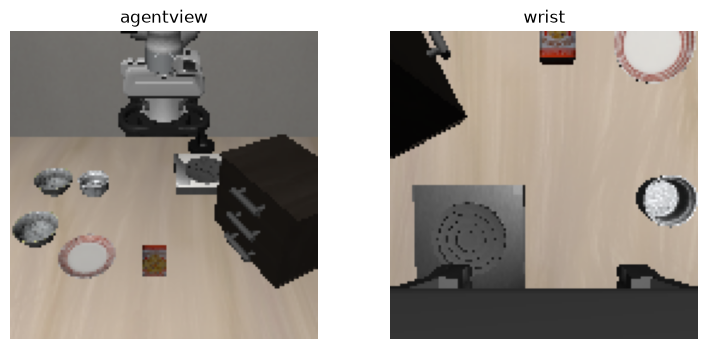

In [12]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, image, title in zip(axes, observation['images'], ['agentview', 'wrist']):
    ax.imshow(image); ax.set_title(title); ax.axis('off')
plt.show()

In [13]:
action = policy.action()
action

{'base': array([ 1.7406669e-01,  3.5959327e-01,  1.6615005e-01,  3.1061505e-04,
        -6.2650844e-02, -2.4616294e-02, -1.0000000e+00], dtype=float32),
 'unit_residual': array([0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 'executed_action': array([ 1.7406669e-01,  3.5959327e-01,  1.6615005e-01,  3.1061505e-04,
        -6.2650844e-02, -2.4616294e-02, -1.0000000e+00], dtype=float32),
 'checked_against_recorded_first_action': True}

`executed_action` — семь bounded команд OSC: translation, rotation и gripper. Chunk длиной50 предсказывается заново каждые5 исполненных actions. Rollout ниже переиспользует проверенный финальный episode; видео включает обе камеры и terminal frame.

In [14]:
rollout = policy.rollout()
{k: rollout[k] for k in ['method', 'task', 'seed', 'success', 'length', 'reset_hash', 'trajectory_hash']}

{'method': 'expert',
 'task': 'D1',
 'seed': 30000,
 'success': True,
 'length': 114,
 'reset_hash': 'fdca0d2f5f05645af644c339c68139b679a2d8cc2f6b83112d224b3896d6acbe',
 'trajectory_hash': '484828c44be3192a8bee6ea533aa439a88243828696ee26fa67de732d8a42591'}

In [15]:
policy.video(rollout)

In [16]:
policy.success_rates()

{'D0': {'n': 50,
  'successes': 0,
  'success_rate': 0.0,
  'wilson_95ci': [6.938893903907228e-18, 0.07134759913335872],
  'mean_episode_length': 220.0},
 'D1': {'n': 50,
  'successes': 19,
  'success_rate': 0.38,
  'wilson_95ci': [0.25862789310193596, 0.5184955306900703],
  'mean_episode_length': 179.82}}

In [17]:
policy.close()
del policy

### Что именно заморожено?

В `sft/expert/scope.json` перечислены все tensors и trainable flags. PaliGemma (vision encoder, multimodal projector и language model) не входит в optimizer. На каждом сохранении hashes frozen weights сверяются с началом стадии; normalization тоже проверяется побайтово. Unused expert lm_head унаследован из официального PyTorch представления, не участвует в loss; это не адаптер LoRA.

## 3. Residual RL

Загрузим веса и ту же D0 normalization. Создадим D1-сцену с сохранённым reset state и проверим hash. Затем вычислим первое действие и сверим его с финальным эпизодом.

In [18]:
policy = SeminarPolicy('residual')
print('Checkpoint:', policy.checkpoint)
print('D0 normalization SHA256:', policy.norm)

Checkpoint: /workspace/pi0_three/rl/final
D0 normalization SHA256: a06c2e745bf91d8dd6a3fa6377560d3104e6cad621da4ecebe1372c74bbb388e


In [19]:
observation = policy.scene('D1', seed=30000)
print('Prompt:', observation['prompt'])
print('State:', observation['state'])
print('Images:', observation['images'].shape, observation['images'].dtype)
print('Reset SHA256:', observation['reset_hash'])
print('Initial observation SHA256:', observation['initial_observation_hash'])

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


Prompt: pick up the black bowl next to the plate and place it on the plate
State: [-2.0846467e-01  2.4891632e-12  1.1732795e+00  3.1403394e+00
  7.7350385e-04 -8.9222006e-02  3.8722824e-02 -3.8722765e-02]
Images: (2, 128, 128, 3) uint8
Reset SHA256: fdca0d2f5f05645af644c339c68139b679a2d8cc2f6b83112d224b3896d6acbe
Initial observation SHA256: b0dd88d8a24a45b3b352663860ed9530a1d70ea025c272f3374ac59a5c19ef21


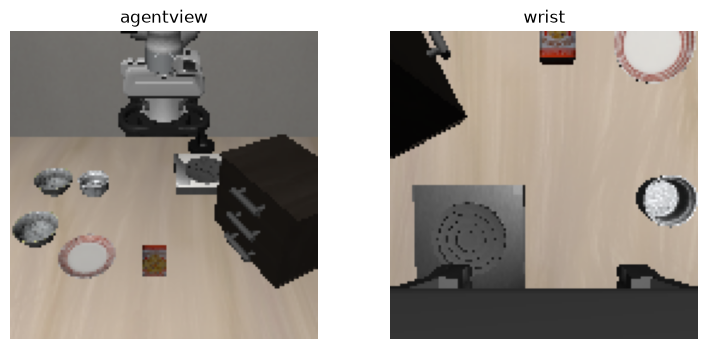

In [20]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, image, title in zip(axes, observation['images'], ['agentview', 'wrist']):
    ax.imshow(image); ax.set_title(title); ax.axis('off')
plt.show()

In [21]:
action = policy.action()
action

{'base': array([ 2.0404871e-01,  9.8241091e-02,  4.7492526e-02, -3.9412369e-04,
        -3.2147588e-03, -3.4205548e-02, -1.0000000e+00], dtype=float32),
 'unit_residual': array([ 0.00142457,  0.1825019 , -0.14598574,  0.11826609, -0.00491833,
        -0.13332717, -0.11545607], dtype=float32),
 'executed_action': array([ 0.20689784,  0.4632449 , -0.24447894,  0.23613806, -0.01305141,
        -0.3008599 , -1.        ], dtype=float32),
 'checked_against_recorded_first_action': True}

`executed_action` — семь bounded команд OSC: translation, rotation и gripper. Chunk длиной50 предсказывается заново каждые5 исполненных actions. Rollout ниже переиспользует проверенный финальный episode; видео включает обе камеры и terminal frame.

In [22]:
rollout = policy.rollout()
{k: rollout[k] for k in ['method', 'task', 'seed', 'success', 'length', 'reset_hash', 'trajectory_hash']}

{'method': 'residual',
 'task': 'D1',
 'seed': 30000,
 'success': False,
 'length': 220,
 'reset_hash': 'fdca0d2f5f05645af644c339c68139b679a2d8cc2f6b83112d224b3896d6acbe',
 'trajectory_hash': '621fcd00c4a880311c63cd51121ff8ad3a362d3a6a66d924aecdd6ccc596740e'}

In [23]:
policy.video(rollout)

In [24]:
policy.success_rates()

{'D0': {'n': 50,
  'successes': 0,
  'success_rate': 0.0,
  'wilson_95ci': [6.938893903907228e-18, 0.07134759913335872],
  'mean_episode_length': 220.0},
 'D1': {'n': 50,
  'successes': 0,
  'success_rate': 0.0,
  'wilson_95ci': [6.938893903907228e-18, 0.07134759913335872],
  'mean_episode_length': 220.0}}

In [25]:
policy.close()
del policy

### Две модели во время warmup

В residual всегда остаётся исходная frozen D0-база. Ранний D1 full-SFT checkpoint только исполняет warmup actions. Два chunk caches независимы, D0 action вычисляется на каждом посещённом состоянии. `clip(a_D0 + 2 × residual, -1,1)` позволяет воспроизвести teacher action, что проверено в trace.

Offline Cal-QL:1000 updates; teacher warmup:20 episodes с обновлениями actor/critic/temperature; online:50000 active transitions, OTF collection, probe_fraction0. Evaluation использует deterministic actor.

Shaping: `r = r_success + .1 × (.99 × Phi(next) − Phi(state))`. Phi зависит от reach, grasp, lift/transport нужной миски. Terminal Phi равна0, включая конечный горизонт. Один код пересчитывает rewards и MC returns; исходный LIBERO success predicate сохраняется. State potential используется только при обучении; actor получает камеры, proprioception и base action.

## Итоговая таблица и paired comparisons

В каждой ячейке **N=50**. Wilson95% CI отражает неопределённость SR для сцен; одна training seed не измеряет вариативность самого обучения. Paired differences сопоставляют одинаковые scenes/noise, exact McNemar использует discordant pairs; Holm adjustment учитывает шесть сравнений. Не объединяем correlated episodes между методами в один размер выборки.

In [26]:
import pandas as pd
results = ROOT/'experiments/pi0_d0_d1_three_adaptations/results'
pd.read_csv(results/'success_rates.csv')

,method,task,n,successes,success_rate,wilson_low,wilson_high
0,full,D0,50,0,0.00,6.938894e-18,0.071348
1,full,D1,50,20,0.40,2.760839e-01,0.538186
2,expert,D0,50,0,0.00,6.938894e-18,0.071348
3,expert,D1,50,19,0.38,2.586279e-01,0.518496
4,residual,D0,50,0,0.00,6.938894e-18,0.071348
5,residual,D1,50,0,0.00,6.938894e-18,0.071348


In [27]:
pd.DataFrame(json.loads((results/'paired_comparisons.json').read_text()))

,n,rescue,harm,gain_pp,bootstrap_95_pp,bootstrap_draws,bootstrap_seed,exact_boundary_95_pp,task,before,after,mcnemar_exact_p,mcnemar_holm_p
0,50,0,0,0.0,"[0.0, 0.0]",10000,0,"[-5.815507911697226, 5.815507911697226]",D0,full,expert,1.000000,1.000000
1,50,0,0,0.0,"[0.0, 0.0]",10000,0,"[-5.815507911697226, 5.815507911697226]",D0,full,residual,1.000000,1.000000
2,50,0,0,0.0,"[0.0, 0.0]",10000,0,"[-5.815507911697226, 5.815507911697226]",D0,expert,residual,1.000000,1.000000
3,50,1,2,-2.0,"[-10.0, 4.0]",10000,0,None,D1,full,expert,1.000000,1.000000
4,50,0,20,-40.0,"[-54.0, -26.0]",10000,0,None,D1,full,residual,0.000002,0.000011
5,50,0,19,-38.0,"[-52.0, -24.0]",10000,0,None,D1,expert,residual,0.000004,0.000019


In [28]:
completeness = json.loads((results/'completeness.json').read_text())
assert completeness['episodes'] == completeness['videos'] == 300
completeness

{'passed': True,
 'episodes': 300,
 'videos': 300,
 'cells': 6,
 'n_per_cell': 50,
 'terminal_frames_verified': True,
 'reset_hashes_equal': True,
 'initial_observation_hashes_equal': True,
 'common_flow_noise_prefixes_equal': True}

## Обсуждение для студентов

1. Каков tradeoff D1 acquisition и D0 retention? Какие paired differences убедительны с учётом CI?
2. Почему full/expert SFT имеют одинаковый бюджет, но RL нельзя считать тем же объёмом supervision?
3. Как широкая residual scale2 и simulator-state shaping ограничивают интерпретацию?
4. Почему эти результаты не являются OOD generalization и не измеряют variability между training seeds?

[Краткий отчёт](REPORT.md) и [все 300 видео](https://huggingface.co/qrvmil/pi0-d0-d1-three-adaptations-20261020/tree/main/final).